# Fase 4 — Minería de Datos: Ajuste Fino Parcial de SAM2 sobre el Grupo Control

## 1. Introducción

### 1.1. Objetivo

Este notebook implementa la **Fase de Minería de Datos** de la metodología **Knowledge Discovery in Databases (KDD)** (Fayyad et al., 1996) aplicada al presente proyecto: el ajuste fino parcial (*partial fine-tuning*) de **Segment Anything Model 2** (SAM2, Ravi et al., 2024) sobre el dataset YOLO de segmentación producido por la Fase 3 (Transformación) para el **Grupo Control**.

Su única responsabilidad es entrenar y guardar un modelo especializado, `SAM2-Control`, capaz de segmentar lesiones cariosas a partir de imágenes que **no** atravesaron ningún pipeline de optimización visual (únicamente el redimensionado por *letterbox* exigido por SAM2). Este notebook no ejecuta selección, preprocesamiento, transformación de datos ni evaluación comparativa entre grupos: recibe como única entrada el dataset ya construido por la Fase 3 y produce como salida un *checkpoint* entrenado, sus métricas de validación por época y las figuras de las curvas de entrenamiento.

### 1.2. Relación con la metodología KDD

Dentro de KDD, la fase de Minería de Datos aplica el algoritmo de aprendizaje sobre los datos ya transformados, con el propósito de producir un modelo capaz de generalizar el patrón de interés — en este caso, la morfología y textura de las lesiones cariosas — a partir de las anotaciones disponibles. Este notebook no decide qué datos entran al experimento ni cómo se preparan visualmente; esas decisiones ya fueron tomadas y fijadas por la Fase 3. Su responsabilidad se limita a la especialización del modelo fundacional sobre la representación que la fase anterior definió para el Grupo Control.

### 1.3. Grupo correspondiente y comparabilidad

Este archivo corresponde exclusivamente al **Grupo Control**. Consume el dataset ubicado en `.../Fase 3/.../Salida/Control/{train,valid,test}` y su `data.yaml` asociado, es decir, las imágenes originales del corpus curado, sin ninguna etapa de optimización visual salvo el redimensionado homogéneo a 1024×1024 mediante *letterbox*.

Su comparabilidad con el notebook gemelo del **Grupo Experimental** no depende de ninguna decisión tomada en este archivo, sino de una restricción de diseño externa a él: ambos notebooks son copias funcionalmente idénticas salvo en (a) la ruta de entrada del `data.yaml`, (b) las rutas de salida de *checkpoints*, *logs* y figuras, y (c) los textos descriptivos que identifican el grupo. Arquitectura, congelamiento de submódulos, función de pérdida y sus pesos, optimizador, tasa de aprendizaje, *scheduler*, tamaño de lote, número de épocas, semilla, criterio de *early stopping*, criterio de selección del mejor *checkpoint*, estrategia de generación de prompts, augmentaciones y precisión numérica son literalmente iguales en ambos archivos. Esta paridad es la condición que permite que, en la Fase 5, cualquier diferencia de desempeño observada entre `SAM2-Control` y `SAM2-Experimental` sea atribuible exclusivamente al pipeline de optimización visual de la Fase 3.

---

## 2. Configuración del entorno

### 2.1. Instalación de dependencias

El ajuste fino requiere el paquete oficial de SAM2, un motor de augmentación geométrica vectorizado (`albumentations`), manipulación de imágenes (`opencv-python`), cómputo numérico (`numpy`, `torch`) y parseo de `data.yaml` (`pyyaml`). Se instala únicamente lo que no esté preinstalado en el entorno de ejecución (Google Colab), sin forzar actualizaciones que puedan generar conflictos con la versión de `torch` ya provista por el entorno.



In [ ]:
!pip install -q "git+https://github.com/facebookresearch/sam2.git"
!pip install -q albumentations opencv-python pyyaml

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


### 2.2. Montaje del almacenamiento persistente

El dataset de entrada (salida de la Fase 3) y las salidas de este notebook (*checkpoints*, *logs*, figuras) residen en Google Drive. El almacenamiento se monta antes de definir o crear cualquier ruta bajo `/content/drive`.

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 2.3. Importaciones

In [ ]:
import os
# Requerido para determinismo de cuBLAS; debe fijarse ANTES de la primera llamada a CUDA.
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import json
import random
import time
import hashlib
import platform
import importlib.metadata
import datetime as dt
from contextlib import contextmanager
from pathlib import Path
from dataclasses import dataclass, field, fields
from typing import Optional

import cv2
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import albumentations as A

from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor

---

## 3. Configuración centralizada

### 3.1. Estructura de configuración

Se define una única estructura de configuración, congelada (`frozen=True`), con todas las rutas y todos los hiperparámetros del entrenamiento declarados de forma explícita como constantes documentadas. Ningún hiperparámetro queda implícito ni codificado como número mágico en el resto del notebook. Esta misma estructura, con los mismos valores en todos los campos salvo los de ruta señalados en la Sección 1.3, se replica literalmente en el notebook del Grupo Experimental.

In [ ]:
BASE_DRIVE = "/content/drive/MyDrive/KDD_Caries"

@dataclass(frozen=True)
class Phase4Config:
    """Configuración centralizada de rutas e hiperparámetros de la Fase 4 — Grupo Control."""

    # --- Identificación del grupo (único en este notebook, junto con las rutas de datos) ---
    group_name: str = "Control"
    contraparte_group_name: str = "Experimental"

    # --- Rutas de entrada (permitido variar entre notebooks) ---
    data_yaml_path: Path = Path(
        BASE_DRIVE + "/Fase 3/Salida/Control/data.yaml"
    )
    # data.yaml del grupo contrario: SOLO se usa en la prueba de humo 3 (aleatoriedad común entre brazos).
    contraparte_data_yaml_path: Path = Path(
        BASE_DRIVE + "/Fase 3/Salida/Experimental/data.yaml"
    )

    # --- Rutas de salida: cada semilla y grupo tienen su carpeta ---
    base_salida: Path = Path(BASE_DRIVE + "/Fase 4/Semilla 42")

    @property
    def output_root(self) -> Path:
        return self.base_salida / "Salida" / self.group_name

    @property
    def checkpoints_dir(self) -> Path:
        return self.output_root / "Checkpoints"

    @property
    def logs_dir(self) -> Path:
        return self.output_root / "Logs"

    @property
    def figures_dir(self) -> Path:
        return self.output_root / "Figuras"

    # --- Pesos preentrenados de SAM2 (idéntico en ambos notebooks) ---
    sam2_checkpoint_path: Path = Path(
        BASE_DRIVE + "/Fase 4/Pesos-Base/sam2.1_hiera_large.pt"
    )
    sam2_checkpoint_url: str = (
        "https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_large.pt"
    )
    sam2_model_cfg: str = "configs/sam2.1/sam2.1_hiera_l.yaml"

    # --- Reproducibilidad: CAMBIAR SOLO `seed` entre corridas (56, 42, 25); igual en ambos notebooks ---
    seed: int = 42
    cudnn_deterministic: bool = True
    cudnn_benchmark: bool = False

    # --- Geometría de entrada (idéntico: heredado de la Fase 3) ---
    image_size: int = 1024
    splits: tuple = ("train", "valid", "test")

    # --- Congelamiento de submódulos (idéntico) ---
    freeze_image_encoder: bool = True
    freeze_prompt_encoder: bool = True
    freeze_mask_decoder: bool = False

    # --- Estrategia de prompting (idéntico) ---
    prompt_type: str = "bbox"
    prompt_bbox_jitter_frac: float = 0.05     # traslación de la caja, fracción de su ancho/alto
    prompt_bbox_padding_px: int = 4
    prompt_jitter_train: bool = True          # el jitter solo se aplica en entrenamiento
    prompt_jitter_valid: bool = False         # validación con la misma caja que se usa en prueba (sin jitter)

    # --- Función de pérdida híbrida (idéntico) ---
    loss_dice_weight: float = 0.7
    loss_focal_weight: float = 0.3
    focal_gamma: float = 2.0
    focal_alpha: float = 0.85

    # --- Augmentación geométrica (idéntico; solo train) ---
    aug_hflip_prob: float = 0.5
    aug_rotate_limit_deg: float = 10.0
    aug_rotate_prob: float = 0.5
    aug_shift_scale_rotate_prob: float = 0.5
    aug_shift_limit: float = 0.05
    aug_scale_limit: float = 0.10

    # --- Optimización (idéntico) ---
    optimizer_name: str = "AdamW"
    learning_rate: float = 1e-4
    weight_decay: float = 1e-4
    lr_scheduler_name: str = "CosineAnnealingLR"
    lr_scheduler_t_max_epochs: int = 80      # T_max igual al número de épocas
    lr_scheduler_eta_min: float = 1e-6

    # --- Régimen de entrenamiento (idéntico) ---
    batch_size: int = 4
    num_epochs: int = 80                     # sin early stopping
    num_workers: int = 2
    ema_decay: float = 0.999                  # media móvil exponencial de los pesos del decodificador
    grad_clip_norm: float = 1.0               # recorte de gradiente (0 lo desactiva)
    upsample_deterministico: bool = True      # reescalado bilineal por multiplicación de matrices

    # --- Precisión numérica (idéntico) ---
    mixed_precision: str = "bf16"  # {"fp32", "fp16", "bf16"}

    # --- Control de ejecución y pruebas de humo ---
    ejecutar_pruebas_humo: bool = True
    ejecutar_entrenamiento: bool = True
    n_lesiones_humo: int = 50
    pruebas_humo_lotes: int = 20

    # --- Dispositivo ---
    device: str = "cuda" if torch.cuda.is_available() else "cpu"

    def configuracion_como_dict(self) -> dict:
        d = {f.name: str(getattr(self, f.name)) for f in fields(self)}
        d.update({"output_root": str(self.output_root), "checkpoints_dir": str(self.checkpoints_dir),
                  "logs_dir": str(self.logs_dir), "figures_dir": str(self.figures_dir)})
        return d

CONFIG = Phase4Config()

for directorio in (CONFIG.checkpoints_dir, CONFIG.logs_dir, CONFIG.figures_dir):
    directorio.mkdir(parents=True, exist_ok=True)

print(f"Configuración cargada para el Grupo {CONFIG.group_name} (semilla {CONFIG.seed}).")
print(f"data.yaml de entrada: {CONFIG.data_yaml_path}")
print(f"Checkpoints en:       {CONFIG.checkpoints_dir}")
print(f"Logs en:               {CONFIG.logs_dir}")
print(f"Figuras en:            {CONFIG.figures_dir}")

Configuración cargada para el Grupo Control (semilla 42).
data.yaml de entrada: /content/drive/MyDrive/KDD_Caries/Fase 3/Salida/Control/data.yaml
Checkpoints en:       /content/drive/MyDrive/KDD_Caries/Fase 4/Semilla 42/Salida/Control/Checkpoints
Logs en:               /content/drive/MyDrive/KDD_Caries/Fase 4/Semilla 42/Salida/Control/Logs
Figuras en:            /content/drive/MyDrive/KDD_Caries/Fase 4/Semilla 42/Salida/Control/Figuras


### 3.1b. Huella de configuración (paridad entre notebooks)

Se calcula una huella (SHA-256 abreviado) de todos los campos de `CONFIG` **excepto** los que por diseño difieren entre los dos notebooks (nombre del grupo, rutas de datos y de salida). La huella debe ser **idéntica** en el notebook Control y en el Experimental para una misma semilla; se registra también en los metadatos de cada corrida.

In [ ]:
EXCLUIR_DE_HUELLA = {"group_name", "contraparte_group_name", "data_yaml_path",
                     "contraparte_data_yaml_path", "base_salida"}

def huella_configuracion(cfg: Phase4Config) -> str:
    campos = {f.name: str(getattr(cfg, f.name)) for f in fields(cfg) if f.name not in EXCLUIR_DE_HUELLA}
    return hashlib.sha256(json.dumps(campos, sort_keys=True).encode("utf-8")).hexdigest()[:12]

HUELLA_CONFIG = huella_configuracion(CONFIG)
print(f"Huella de configuración (semilla {CONFIG.seed}): {HUELLA_CONFIG}")
print("Debe coincidir exactamente con la que imprima el notebook del grupo contrario.")

Huella de configuración (semilla 42): 62e744b83283
Debe coincidir exactamente con la que imprima el notebook del grupo contrario.


### 3.2. Fijación de semillas y determinismo

Se fija una única semilla global para `random`, `numpy` y `torch` (CPU y GPU), se desactivan las heurísticas no deterministas de cuDNN y se activan los algoritmos deterministas de PyTorch en modo `warn_only`. Fijar la semilla global **no basta** para controlar la augmentación ni el jitter (ver Secciones 5 y 6): esos componentes derivan su aleatoriedad de `(semilla, época, índice)`. Este bloque es idéntico, con el mismo valor de semilla, en ambos notebooks.

In [ ]:
import inspect
import sam2.modeling.sam.transformer as _sam2_transformer

def fijar_semilla(seed: int, deterministic: bool, benchmark: bool) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = deterministic
    torch.backends.cudnn.benchmark = benchmark
    # warn_only: las operaciones sin implementación determinista avisan en lugar de fallar.
    torch.use_deterministic_algorithms(True, warn_only=True)

    # los kernels rápidos de atención se dejan activos globalmente (el forward del encoder congelado,
    # sin backward, es determinista). El kernel "math" se impone SOLO en el decoder (ver forward_batch).
    torch.backends.cuda.enable_flash_sdp(True)
    torch.backends.cuda.enable_mem_efficient_sdp(True)
    torch.backends.cuda.enable_math_sdp(True)
    # Sin TF32 (afecta al matmul float32 de subir_bilineal y a las convoluciones).
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False

# En versiones antiguas de SAM2 la atención del decoder va envuelta en sdp_kernel(...), que anula el contexto
# de forward_batch. En ese caso se fuerzan las constantes del propio módulo (que solo afectan al decoder).
if "sdp_kernel" in inspect.getsource(_sam2_transformer):
    for _nombre, _valor in (("USE_FLASH_ATTN", False), ("MATH_KERNEL_ON", True), ("ALLOW_ALL_KERNELS", False)):
        if hasattr(_sam2_transformer, _nombre):
            setattr(_sam2_transformer, _nombre, _valor)
    print("SAM2 usa sdp_kernel(...): constantes del módulo forzadas a kernel math (solo decoder).")
else:
    print("SAM2 llama directamente a F.scaled_dot_product_attention: el kernel math se impone en forward_batch.")

fijar_semilla(CONFIG.seed, CONFIG.cudnn_deterministic, CONFIG.cudnn_benchmark)
print(f"Semilla global fijada en SEED={CONFIG.seed} (cuDNN determinista={CONFIG.cudnn_deterministic}, "
      f"algoritmos deterministas activados con warn_only=True).")
print(f"CUBLAS_WORKSPACE_CONFIG={os.environ.get('CUBLAS_WORKSPACE_CONFIG')}")
print(f"SDPA global -> flash={torch.backends.cuda.flash_sdp_enabled()} | "
      f"mem_efficient={torch.backends.cuda.mem_efficient_sdp_enabled()} | "
      f"math={torch.backends.cuda.math_sdp_enabled()} | "
      f"TF32 matmul={torch.backends.cuda.matmul.allow_tf32} | TF32 cudnn={torch.backends.cudnn.allow_tf32}")

SAM2 llama directamente a F.scaled_dot_product_attention: el kernel math se impone en forward_batch.
Semilla global fijada en SEED=42 (cuDNN determinista=True, algoritmos deterministas activados con warn_only=True).
CUBLAS_WORKSPACE_CONFIG=:4096:8
SDPA global -> flash=True | mem_efficient=True | math=True | TF32 matmul=False | TF32 cudnn=False


---

## 4. Carga del dataset y verificación de paridad

### 4.1. Lectura de `data.yaml`

In [ ]:
with open(CONFIG.data_yaml_path, "r", encoding="utf-8") as f:
    data_yaml = yaml.safe_load(f)

dataset_root = CONFIG.data_yaml_path.parent
split_dirs = {
    split: {
        "images": dataset_root / split / "images",
        "labels": dataset_root / split / "labels",
    }
    for split in CONFIG.splits
}

print(f"Clases declaradas en data.yaml: {data_yaml.get('names')}")

Clases declaradas en data.yaml: ['Caries']


### 4.2. Conteo de muestras por partición y verificación auditable

Se cuenta el número de imágenes y de lesiones (líneas en .txt YOLO) por partición, y se verifica programáticamente que cada imagen tenga su archivo de etiqueta correspondiente y que el conteo total coincida con lo reportado por la Fase 3. Esta celda deja evidencia auditable de que no hubo pérdida ni duplicación de muestras al consumir la salida de la fase anterior.

In [ ]:
conteos = {}
detalle_lesiones = {}

for split, rutas in split_dirs.items():
    imagenes = sorted(p.stem for p in rutas["images"].glob("*.*"))
    etiquetas = sorted(p.stem for p in rutas["labels"].glob("*.txt"))
    faltantes = set(imagenes) - set(etiquetas)
    sobrantes = set(etiquetas) - set(imagenes)

    assert not faltantes, f"Imágenes sin etiqueta en '{split}': {sorted(faltantes)[:5]}..."
    assert not sobrantes, f"Etiquetas sin imagen en '{split}': {sorted(sobrantes)[:5]}..."

    # NUEVO: conteo a nivel de lesión
    n_lesiones = 0
    lesiones_por_imagen = []
    for stem in imagenes:
        label_path = rutas["labels"] / f"{stem}.txt"
        with open(label_path, "r", encoding="utf-8") as f:
            lineas = [l for l in f if l.strip()]
            n_lesiones += len(lineas)
            lesiones_por_imagen.append(len(lineas))

    conteos[split] = {"n_imagenes": len(imagenes), "n_lesiones": n_lesiones}
    detalle_lesiones[split] = lesiones_por_imagen

# Tabla de conteos por partición
df_conteos = pd.DataFrame([
    {"particion": k, "n_imagenes": v["n_imagenes"], "n_lesiones": v["n_lesiones"]}
    for k, v in conteos.items()
])
df_conteos.loc[len(df_conteos)] = ["total", df_conteos["n_imagenes"].sum(), df_conteos["n_lesiones"].sum()]

print(f"Verificación de paridad — Grupo {CONFIG.group_name} — TODAS LAS LESIONES")
print(df_conteos.to_string(index=False))

for split, lista in detalle_lesiones.items():
    arr = np.array(lista)
    print(f"{split}: media lesiones/imagen={arr.mean():.2f}, max={arr.max()}, imágenes con >1 lesión={np.sum(arr>1)} ({np.mean(arr>1)*100:.1f}%)")

# Guardar el conteo en la carpeta de logs
df_conteos.to_csv(CONFIG.logs_dir / f"conteo_instancias_{CONFIG.group_name.lower()}_ALL_LESIONES.csv", index=False)

# Nota de auditoría: el total debe coincidir con Fase 3 Sección 8.1:
# 1039 imágenes / 3606 lesiones totales, test 156 / 564

Verificación de paridad — Grupo Control — TODAS LAS LESIONES
particion  n_imagenes  n_lesiones
    train         727        2455
    valid         156         587
     test         156         564
    total        1039        3606
train: media lesiones/imagen=3.38, max=22, imágenes con >1 lesión=512 (70.4%)
valid: media lesiones/imagen=3.76, max=15, imágenes con >1 lesión=113 (72.4%)
test: media lesiones/imagen=3.62, max=13, imágenes con >1 lesión=108 (69.2%)


---

## 5. Pipeline de augmentación geométrica

### 5.1. Definición del pipeline

Se define un único pipeline de augmentación, aplicado exclusivamente a la partición `train`. Todas las transformaciones son estrictamente geométricas (volteo horizontal, rotación acotada, traslación/escala/rotación combinada dentro de rangos reducidos); ninguna transformación fotométrica (brillo, contraste, saturación, matiz, gamma, ruido sintético, desenfoque, ecualización) se incluye en este pipeline, en ninguno de los dos notebooks. Así, la única diferencia fotométrica entre los grupos es la que introduce el pipeline de la Fase 3.

La semilla de cada muestra se fija con `Compose.set_random_seed`, derivada de `(semilla, época, índice)`, de modo que las transformaciones son idénticas en Control y Experimental. La caja del prompt ya no se transforma como caja: se recalcula desde la máscara transformada, y si la lesión saliera del encuadre se usa la muestra sin augmentar.

In [ ]:
def construir_augmentaciones_geometricas(cfg: Phase4Config, seed: Optional[int] = None) -> A.Compose:
    """Pipeline de augmentación EXCLUSIVAMENTE geométrico, aplicado solo a train.

    Prohibición explícita: no se incluye ninguna transformación fotométrica.
    La caja del prompt NO se transforma aquí: se recalcula desde la máscara transformada.
    `seed` solo se usa en la ruta de reserva (si Compose no ofreciera set_random_seed).
    """
    return A.Compose(
        [
            A.HorizontalFlip(p=cfg.aug_hflip_prob),
            A.Rotate(
                limit=cfg.aug_rotate_limit_deg,
                border_mode=cv2.BORDER_CONSTANT,
                p=cfg.aug_rotate_prob,
            ),
            A.ShiftScaleRotate(
                shift_limit=cfg.aug_shift_limit,
                scale_limit=cfg.aug_scale_limit,
                rotate_limit=0,
                border_mode=cv2.BORDER_CONSTANT,
                p=cfg.aug_shift_scale_rotate_prob,
            ),
        ],
        seed=seed,
    )

train_augmentations = construir_augmentaciones_geometricas(CONFIG)
print("Pipeline de augmentación geométrica construido (train únicamente).")
print("Transformaciones incluidas:", [t.__class__.__name__ for t in train_augmentations.transforms])
print("Semilla por muestra disponible (Compose.set_random_seed):", hasattr(train_augmentations, "set_random_seed"))

Pipeline de augmentación geométrica construido (train únicamente).
Transformaciones incluidas: ['HorizontalFlip', 'Rotate', 'ShiftScaleRotate']
Semilla por muestra disponible (Compose.set_random_seed): True


/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


---

## 6. Construcción del prompt de entrada a SAM2

### 6.1. De polígono YOLO a caja delimitadora con jitter determinista

SAM2 se condiciona mediante *prompts* espaciales (puntos, cajas o máscaras de baja resolución). Este proyecto emplea **cajas delimitadoras** derivadas automáticamente del polígono de segmentación de referencia (ya transformado por la Fase 3 para el lienzo de 1024×1024), con un jitter geométrico leve y determinista para robustecer el decoder frente a variaciones de localización del prompt. Esta función es idéntica, carácter por carácter, en ambos notebooks, y se calcula a partir de las mismas anotaciones.

El jitter es una **traslación** de la caja (mismo desplazamiento en ambas esquinas, hasta ±5 % de su ancho y alto); no modifica su tamaño. Se genera con un generador propio de cada muestra, se aplica **solo en entrenamiento** y la validación usa la caja con margen fijo, igual que la evaluación en prueba.

In [ ]:
def poligono_a_bbox(poligono_normalizado: np.ndarray, image_size: int) -> np.ndarray:
    """Convierte un polígono YOLO normalizado (N, 2) a bbox absoluta [x1, y1, x2, y2]."""
    coords_abs = poligono_normalizado * image_size
    x1, y1 = coords_abs.min(axis=0)
    x2, y2 = coords_abs.max(axis=0)
    return np.array([x1, y1, x2, y2], dtype=np.float32)

def mascara_a_bbox(mascara: np.ndarray) -> np.ndarray:
    """Caja [x1, y1, x2, y2] que envuelve los píxeles positivos de la máscara (recalculada tras augmentar)."""
    ys, xs = np.nonzero(mascara)
    return np.array([xs.min(), ys.min(), xs.max() + 1, ys.max() + 1], dtype=np.float32)

def aplicar_jitter_determinista(bbox: np.ndarray, cfg: Phase4Config, rng: np.random.Generator,
                                jitter: bool = True) -> np.ndarray:
    """Aplica padding fijo y, si `jitter`, una traslación aleatoria de la caja (bajo `rng`).

    `rng` es un generador propio de cada muestra, derivado de (semilla, época, índice, partición);
    por eso el resultado no depende de los workers ni del orden de los lotes.
    """
    x1, y1, x2, y2 = bbox
    x1 -= cfg.prompt_bbox_padding_px
    y1 -= cfg.prompt_bbox_padding_px
    x2 += cfg.prompt_bbox_padding_px
    y2 += cfg.prompt_bbox_padding_px

    if jitter:
        ancho, alto = x2 - x1, y2 - y1
        jitter_x = rng.uniform(-cfg.prompt_bbox_jitter_frac, cfg.prompt_bbox_jitter_frac) * ancho
        jitter_y = rng.uniform(-cfg.prompt_bbox_jitter_frac, cfg.prompt_bbox_jitter_frac) * alto
        x1 += jitter_x
        y1 += jitter_y
        x2 += jitter_x
        y2 += jitter_y

    return np.clip(np.array([x1, y1, x2, y2], dtype=np.float32), 0, cfg.image_size - 1)

print(f"Estrategia de prompting: '{CONFIG.prompt_type}', padding={CONFIG.prompt_bbox_padding_px}px, "
      f"jitter=±{CONFIG.prompt_bbox_jitter_frac * 100:.1f}% (train={CONFIG.prompt_jitter_train}, "
      f"valid={CONFIG.prompt_jitter_valid}).")

Estrategia de prompting: 'bbox', padding=4px, jitter=±5.0% (train=True, valid=False).


### 6.2. Dataset de PyTorch

In [ ]:
class CariesSegDataset(Dataset):
    """Dataset YOLO de segmentación de caries: cada línea del .txt es una lesión (instancia independiente).

    Toda la aleatoriedad de una muestra (augmentación y jitter) se deriva de
    (semilla, época, índice, partición). No hay generadores secuenciales compartidos:
    el resultado es idéntico con cualquier número de workers, en cualquier orden de lotes
    y entre los notebooks Control y Experimental.
    """

    STREAMS = {"train": 1, "valid": 2, "test": 3}

    def __init__(self, split: str, cfg: Phase4Config, augment: bool, jitter: bool, data_root: Optional[Path] = None):
        self.cfg = cfg
        self.split = split
        self.augment = augment
        self.jitter = jitter
        self.epoch = 0
        self.stream = self.STREAMS[split]
        raiz = Path(data_root) if data_root is not None else Path(cfg.data_yaml_path).parent
        self.images_dir = raiz / split / "images"
        self.labels_dir = raiz / split / "labels"
        self.archivos_imagen = sorted(p.stem for p in self.images_dir.glob("*.*"))

        self.indice_lesiones = []
        for stem in self.archivos_imagen:
            with open(self.labels_dir / f"{stem}.txt", "r", encoding="utf-8") as f:
                for idx_lesion, linea in enumerate(f):
                    linea = linea.strip()
                    if not linea:
                        continue
                    valores = list(map(float, linea.split()[1:]))
                    poligono = np.array(valores, dtype=np.float32).reshape(-1, 2)
                    self.indice_lesiones.append((stem, idx_lesion, poligono))

        self.transform = train_augmentations if augment else None
        print(f"[{split}] Imágenes: {len(self.archivos_imagen)} | Lesiones (instancias): {len(self.indice_lesiones)}")

    def set_epoch(self, epoch: int) -> None:
        """Debe llamarse antes de iterar cada época (los workers reciben la copia actualizada)."""
        self.epoch = int(epoch)

    def _rng(self, idx: int) -> np.random.Generator:
        epoca = self.epoch if self.augment else 0
        return np.random.default_rng([int(self.cfg.seed), int(epoca), int(idx), int(self.stream)])

    def __len__(self) -> int:
        return len(self.indice_lesiones)

    def __getitem__(self, idx: int):
        stem, idx_lesion, poligono_norm = self.indice_lesiones[idx]
        img_path = next(self.images_dir.glob(f"{stem}.*"))
        rng = self._rng(idx)

        imagen = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
        mascara = np.zeros((self.cfg.image_size, self.cfg.image_size), dtype=np.uint8)
        poligono_abs = (poligono_norm * self.cfg.image_size).astype(np.int32)
        cv2.fillPoly(mascara, [poligono_abs], 1)
        bbox = poligono_a_bbox(poligono_norm, self.cfg.image_size)

        if self.transform is not None:
            semilla_muestra = int(rng.integers(0, 2**31 - 1))
            if hasattr(self.transform, "set_random_seed"):
                self.transform.set_random_seed(semilla_muestra)
                transformado = self.transform(image=imagen, mask=mascara)
            else:  # ruta de reserva
                transformado = construir_augmentaciones_geometricas(self.cfg, seed=semilla_muestra)(
                    image=imagen, mask=mascara)
            if transformado["mask"].sum() > 0:      # si la lesión sale del encuadre se usa la muestra sin augmentar
                imagen, mascara = transformado["image"], transformado["mask"]
                bbox = mascara_a_bbox(mascara)      # caja recalculada desde la máscara transformada

        bbox_prompt = aplicar_jitter_determinista(bbox, self.cfg, rng, jitter=self.jitter)

        return {
            "image": torch.from_numpy(imagen).permute(2, 0, 1).float() / 255.0,
            "mask": torch.from_numpy(mascara).float(),
            "bbox_prompt": torch.from_numpy(bbox_prompt),
            "stem": stem,
            "lesion_idx": idx_lesion,
            "image_id": stem,
        }

def worker_init_fn(worker_id: int) -> None:
    """Semillas de los workers (no afectan a las muestras, cuya aleatoriedad es por índice; es una salvaguarda)."""
    s = CONFIG.seed * 1000 + worker_id
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)

def crear_train_loader(dataset: Dataset, cfg: Phase4Config) -> DataLoader:
    """Generador propio para el barajado: mismo orden en ambos grupos. No usar persistent_workers:
    set_epoch() no se propagaría a workers ya creados."""
    g = torch.Generator()
    g.manual_seed(cfg.seed)
    return DataLoader(dataset, batch_size=cfg.batch_size, shuffle=True, generator=g,
                      num_workers=cfg.num_workers, drop_last=True, worker_init_fn=worker_init_fn)

def crear_valid_loader(dataset: Dataset, cfg: Phase4Config) -> DataLoader:
    return DataLoader(dataset, batch_size=cfg.batch_size, shuffle=False,
                      num_workers=cfg.num_workers, drop_last=False, worker_init_fn=worker_init_fn)

train_dataset = CariesSegDataset("train", CONFIG, augment=True, jitter=CONFIG.prompt_jitter_train)
valid_dataset = CariesSegDataset("valid", CONFIG, augment=False, jitter=CONFIG.prompt_jitter_valid)
train_loader = crear_train_loader(train_dataset, CONFIG)
valid_loader = crear_valid_loader(valid_dataset, CONFIG)

print(f"Grupo {CONFIG.group_name} — train: {len(train_dataset)} lesiones, valid: {len(valid_dataset)} lesiones")
print("Conteo esperado: train 2455 lesiones, valid 587 lesiones")

[train] Imágenes: 727 | Lesiones (instancias): 2455
[valid] Imágenes: 156 | Lesiones (instancias): 587
Grupo Control — train: 2455 lesiones, valid: 587 lesiones
Conteo esperado: train 2455 lesiones, valid 587 lesiones


---

## 7. Carga del modelo SAM2 y congelamiento de submódulos

### 7.1. Descarga y carga del modelo preentrenado

Los pesos preentrenados de SAM2 no se asumen presentes en el almacenamiento persistente: se descargan de forma programática desde la publicación oficial del repositorio `facebookresearch/sam2` la primera vez que se ejecuta el notebook, y se cachean en `sam2_checkpoint_path` para no repetir la descarga en ejecuciones posteriores. Se verifica la descarga por tamaño de archivo antes de intentar cargar los pesos, para no continuar con un archivo truncado ante una interrupción de red.

In [ ]:
import urllib.request

def descargar_checkpoint_sam2(cfg: Phase4Config) -> None:
    """Descarga el checkpoint oficial de SAM2 si no existe localmente o quedó incompleto."""
    cfg.sam2_checkpoint_path.parent.mkdir(parents=True, exist_ok=True)

    if cfg.sam2_checkpoint_path.exists() and cfg.sam2_checkpoint_path.stat().st_size > 0:
        print(f"Checkpoint SAM2 ya presente en caché: {cfg.sam2_checkpoint_path} "
              f"({cfg.sam2_checkpoint_path.stat().st_size / 1e6:.1f} MB). Se omite la descarga.")
        return

    print(f"Descargando pesos preentrenados de SAM2 desde: {cfg.sam2_checkpoint_url}")
    ruta_temporal = cfg.sam2_checkpoint_path.with_suffix(".part")
    try:
        urllib.request.urlretrieve(cfg.sam2_checkpoint_url, ruta_temporal)
        ruta_temporal.rename(cfg.sam2_checkpoint_path)
    except Exception as error:
        if ruta_temporal.exists():
            ruta_temporal.unlink()
        raise RuntimeError(
            f"No se pudo descargar el checkpoint de SAM2 desde {cfg.sam2_checkpoint_url}. "
            "Verificar conectividad de red del entorno de ejecución."
        ) from error

    print(f"Descarga completa: {cfg.sam2_checkpoint_path} "
          f"({cfg.sam2_checkpoint_path.stat().st_size / 1e6:.1f} MB).")

descargar_checkpoint_sam2(CONFIG)
print(f"Pesos base de SAM2 disponibles en: {CONFIG.sam2_checkpoint_path}")

Checkpoint SAM2 ya presente en caché: /content/drive/MyDrive/KDD_Caries/Fase 4/Pesos-Base/sam2.1_hiera_large.pt (898.1 MB). Se omite la descarga.
Pesos base de SAM2 disponibles en: /content/drive/MyDrive/KDD_Caries/Fase 4/Pesos-Base/sam2.1_hiera_large.pt


### 7.2. Congelamiento explícito de submódulos

El **Image Encoder** permanece congelado en su totalidad; el **Prompt Encoder** permanece congelado, dado que los prompts se generan de forma determinista a partir de anotaciones y no requieren adaptación de sus embeddings; el **Mask Decoder** permanece entrenable, como único componente que se especializa en los patrones morfológicos y texturales de las lesiones cariosas.

In [ ]:
def aplicar_congelamiento(modelo, cfg: Phase4Config) -> None:
    for parametro in modelo.image_encoder.parameters():
        parametro.requires_grad = not cfg.freeze_image_encoder

    for parametro in modelo.sam_prompt_encoder.parameters():
        parametro.requires_grad = not cfg.freeze_prompt_encoder

    for parametro in modelo.sam_mask_decoder.parameters():
        parametro.requires_grad = not cfg.freeze_mask_decoder

def crear_modelo():
    """Construye SAM2 desde los pesos base y aplica el congelamiento (se reutiliza en las pruebas de humo)."""
    modelo = build_sam2(CONFIG.sam2_model_cfg, str(CONFIG.sam2_checkpoint_path), device=CONFIG.device)
    aplicar_congelamiento(modelo, CONFIG)
    return modelo

sam2_model = crear_modelo()
print(f"SAM2 cargado desde: {CONFIG.sam2_checkpoint_path}")

total_params = sum(p.numel() for p in sam2_model.parameters())
entrenables = sum(p.numel() for p in sam2_model.parameters() if p.requires_grad)

print(f"Grupo {CONFIG.group_name}")
print(f"Parámetros totales:      {total_params:,}")
print(f"Parámetros entrenables:  {entrenables:,} ({entrenables / total_params:.2%})")
print(f"Image Encoder congelado: {CONFIG.freeze_image_encoder}")
print(f"Prompt Encoder congelado:{CONFIG.freeze_prompt_encoder}")
print(f"Mask Decoder entrenable: {not CONFIG.freeze_mask_decoder}")

SAM2 cargado desde: /content/drive/MyDrive/KDD_Caries/Fase 4/Pesos-Base/sam2.1_hiera_large.pt
Grupo Control
Parámetros totales:      224,446,642
Parámetros entrenables:  11,737,142 (5.23%)
Image Encoder congelado: True
Prompt Encoder congelado:True
Mask Decoder entrenable: True


---

## 8. Función de pérdida híbrida

### 8.1. Dice Loss + Focal Loss ponderadas

Se combina Dice Loss (Dice, 1945; Milletari et al., 2016) con Focal Loss (Lin et al., 2017), ponderadas según `loss_dice_weight` y `loss_focal_weight` definidos en la configuración centralizada. Los pesos y los parámetros de la Focal Loss son los de la Tabla 4 del artículo.

In [ ]:
class DiceLoss(nn.Module):
    def __init__(self, smooth: float = 1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        probs = torch.sigmoid(logits)
        probs_flat = probs.view(probs.size(0), -1)
        targets_flat = targets.view(targets.size(0), -1)
        interseccion = (probs_flat * targets_flat).sum(dim=1)
        union = probs_flat.sum(dim=1) + targets_flat.sum(dim=1)
        dice = (2.0 * interseccion + self.smooth) / (union + self.smooth)
        return 1.0 - dice.mean()

class FocalLoss(nn.Module):
    def __init__(self, alpha: float, gamma: float):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        bce = F.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        probs = torch.sigmoid(logits)
        p_t = probs * targets + (1 - probs) * (1 - targets)
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        focal = alpha_t * (1 - p_t) ** self.gamma * bce
        return focal.mean()

class DiceFocalLoss(nn.Module):
    def __init__(self, cfg: Phase4Config):
        super().__init__()
        self.dice = DiceLoss()
        self.focal = FocalLoss(alpha=cfg.focal_alpha, gamma=cfg.focal_gamma)
        self.w_dice = cfg.loss_dice_weight
        self.w_focal = cfg.loss_focal_weight

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        return self.w_dice * self.dice(logits, targets) + self.w_focal * self.focal(logits, targets)

criterio = DiceFocalLoss(CONFIG)
print(f"Función de pérdida: Dice(w={CONFIG.loss_dice_weight}) + "
      f"Focal(w={CONFIG.loss_focal_weight}, alpha={CONFIG.focal_alpha}, gamma={CONFIG.focal_gamma})")

Función de pérdida: Dice(w=0.7) + Focal(w=0.3, alpha=0.85, gamma=2.0)


---

## 9. Optimizador, *scheduler*, precisión numérica y semilla

In [ ]:
from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn

usar_bf16 = CONFIG.mixed_precision == "bf16"
usar_fp16 = CONFIG.mixed_precision == "fp16"

def crear_optimizacion(modelo, cfg: Phase4Config):
    """Optimizador, scheduler, EMA del decodificador y scaler (se reutiliza en las pruebas de humo)."""
    parametros = [p for p in modelo.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(parametros, lr=cfg.learning_rate, weight_decay=cfg.weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(
        opt, T_max=cfg.lr_scheduler_t_max_epochs, eta_min=cfg.lr_scheduler_eta_min)
    ema_dec = AveragedModel(modelo.sam_mask_decoder, multi_avg_fn=get_ema_multi_avg_fn(cfg.ema_decay))
    scaler_ = torch.cuda.amp.GradScaler(enabled=usar_fp16)
    return opt, sched, ema_dec, scaler_, parametros

@contextmanager
def pesos_ema(modelo, ema_dec):
    """Sustituye temporalmente los pesos del decodificador por los de la EMA (validar / guardar)."""
    originales = {k: v.detach().clone() for k, v in modelo.sam_mask_decoder.state_dict().items()}
    modelo.sam_mask_decoder.load_state_dict(ema_dec.module.state_dict())
    try:
        yield
    finally:
        modelo.sam_mask_decoder.load_state_dict(originales)

optimizador, scheduler, ema, scaler, parametros_entrenables = crear_optimizacion(sam2_model, CONFIG)

print(f"Optimizador: {CONFIG.optimizer_name} (lr={CONFIG.learning_rate}, wd={CONFIG.weight_decay})")
print(f"Scheduler:   {CONFIG.lr_scheduler_name} (T_max={CONFIG.lr_scheduler_t_max_epochs}, "
      f"eta_min={CONFIG.lr_scheduler_eta_min})")
print(f"EMA del decodificador: decay={CONFIG.ema_decay} | recorte de gradiente: {CONFIG.grad_clip_norm}")
print(f"Precisión:   {CONFIG.mixed_precision}")
print(f"Semilla:     {CONFIG.seed} (determinismo cuDNN activado: {CONFIG.cudnn_deterministic})")

Optimizador: AdamW (lr=0.0001, wd=0.0001)
Scheduler:   CosineAnnealingLR (T_max=80, eta_min=1e-06)
EMA del decodificador: decay=0.999 | recorte de gradiente: 1.0
Precisión:   bf16
Semilla:     42 (determinismo cuDNN activado: True)


/tmp/ipykernel_4253/971863405.py:13: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler_ = torch.cuda.amp.GradScaler(enabled=usar_fp16)


---

## 10. Bucle de entrenamiento

### 10.1. Funciones auxiliares de métricas de validación

In [ ]:
def dice_score(logits: torch.Tensor, targets: torch.Tensor, umbral: float = 0.5, eps: float = 1e-6) -> float:
    preds = (torch.sigmoid(logits) > umbral).float()
    interseccion = (preds * targets).sum(dim=(1, 2))
    union = preds.sum(dim=(1, 2)) + targets.sum(dim=(1, 2))
    dice = (2 * interseccion + eps) / (union + eps)
    return dice.mean().item()

### 10.2. Forward pass con prompts derivados de la anotación

La llamada directa a `modelo.image_encoder(...)` omite dos pasos que SAM2 aplica internamente antes de invocar el decodificador de máscaras: (a) `forward_image`, que proyecta las dos primeras escalas del *feature pyramid* mediante las convoluciones `conv_s0`/`conv_s1` del propio decodificador para producir las *high-resolution features* que habilitan bordes más precisos; y (b) `_prepare_backbone_features`, que aplana y reordena esos mapas de características al formato `(HW, B, C)` que espera el resto del modelo. Esta función replica exactamente la secuencia que usa `SAM2ImagePredictor` en inferencia, adaptada para operar sobre un lote de `B` imágenes con un prompt propio por imagen (de ahí `repeat_image=False`, reservado para el caso de una única imagen con múltiples prompts).

Adicionalmente, el decodificador de SAM2 produce la máscara en baja resolución (`low_res_masks`, a 1/4 del tamaño de entrada: 256×256 para una imagen de 1024×1024), no al tamaño completo del lienzo. El propio `SAM2ImagePredictor` reescala esta salida al tamaño de imagen original como paso de post-procesamiento antes de devolverla; esta función reproduce ese mismo reescalado mediante interpolación bilineal, de modo que los logits queden en la misma resolución (`cfg.image_size`) que las máscaras de referencia y puedan compararse píxel a píxel tanto en la función de pérdida como en las métricas de validación.

El reescalado bilineal de `low_res_masks` a 1024×1024 se realiza fuera de `autocast`, en float32, y por multiplicación de matrices (`subir_bilineal`), matemáticamente equivalente a `F.interpolate(mode='bilinear', align_corners=False)` pero con *backward* determinista en CUDA. Se puede desactivar con `upsample_deterministico=False`.

In [ ]:
from torch.nn.attention import sdpa_kernel, SDPBackend

_cache_R = {}

def _matriz_bilineal(n_in: int, n_out: int, device) -> torch.Tensor:
    """Matriz (n_in, n_out) de interpolación bilineal 1D (align_corners=False)."""
    clave = (n_in, n_out, str(device))
    if clave not in _cache_R:
        with torch.no_grad():
            eye = torch.eye(n_in, device=device, dtype=torch.float32)[None, None]
            _cache_R[clave] = F.interpolate(eye, size=(n_in, n_out), mode="bilinear", align_corners=False)[0, 0]
    return _cache_R[clave]

def subir_bilineal(x: torch.Tensor, size: int) -> torch.Tensor:
    """(B,1,h,w) -> (B,1,size,size). Equivale a F.interpolate(mode='bilinear', align_corners=False),
    pero por multiplicación de matrices, cuyo backward sí es determinista en CUDA."""
    Ry = _matriz_bilineal(x.shape[-2], size, x.device)
    Rx = _matriz_bilineal(x.shape[-1], size, x.device)
    return torch.matmul(Ry.T, torch.matmul(x, Rx))

def forward_batch(modelo, batch, cfg: Phase4Config):
    """Ejecuta la predicción de máscara de SAM2 condicionada al prompt bbox.

    Replica la secuencia interna de SAM2ImagePredictor: forward_image → _prepare_backbone_features →
    separación entre el embedding principal y las high_res_features → sam_mask_decoder con
    repeat_image=False (cada imagen trae su propio prompt). Finalmente reescala la máscara de baja
    resolución al tamaño completo de la imagen. El reescalado se hace fuera de autocast, en float32.
    El encoder (congelado, sin backward) usa los kernels rápidos de atención; el decoder (entrenable)
    usa el kernel "math", cuyo backward es determinista.
    """
    imagenes = batch["image"].to(cfg.device)
    bboxes = batch["bbox_prompt"].to(cfg.device)
    batch_size = imagenes.shape[0]

    dtype_amp = torch.bfloat16 if usar_bf16 else torch.float16 if usar_fp16 else torch.float32
    with torch.autocast(device_type="cuda", dtype=dtype_amp, enabled=(cfg.device == "cuda")):
        backbone_out = modelo.forward_image(imagenes)
        _, vision_feats, _, feat_sizes = modelo._prepare_backbone_features(backbone_out)

        if modelo.directly_add_no_mem_embed:
            vision_feats[-1] = vision_feats[-1] + modelo.no_mem_embed

        # De formato (HW, B, C) a (B, C, H, W) por cada escala del FPN.
        feats = [
            feat.permute(1, 2, 0).view(batch_size, -1, *feat_size)
            for feat, feat_size in zip(vision_feats[::-1], feat_sizes[::-1])
        ][::-1]
        image_embeddings = feats[-1]
        high_res_features = feats[:-1]

        sparse_emb, dense_emb = modelo.sam_prompt_encoder(
            points=None, boxes=bboxes, masks=None,
        )
        with sdpa_kernel(SDPBackend.MATH):
            logits_baja_res, _, _, _ = modelo.sam_mask_decoder(
                image_embeddings=image_embeddings,
                image_pe=modelo.sam_prompt_encoder.get_dense_pe(),
                sparse_prompt_embeddings=sparse_emb,
                dense_prompt_embeddings=dense_emb,
                multimask_output=False,
                repeat_image=False,
                high_res_features=high_res_features,
            )

    logits_baja_res = logits_baja_res.float()
    if cfg.upsample_deterministico:
        logits_mascara = subir_bilineal(logits_baja_res, cfg.image_size)
    else:
        logits_mascara = F.interpolate(logits_baja_res, size=(cfg.image_size, cfg.image_size),
                                       mode="bilinear", align_corners=False)
    return logits_mascara.squeeze(1)

def paso_entrenamiento(modelo, batch, opt, ema_dec, scaler_, parametros) -> float:
    """Un paso de optimización (compartido por el bucle principal y la prueba de humo 2)."""
    opt.zero_grad(set_to_none=True)
    logits = forward_batch(modelo, batch, CONFIG)
    targets = batch["mask"].to(CONFIG.device)
    perdida = criterio(logits, targets)

    if usar_fp16:
        scaler_.scale(perdida).backward()
        if CONFIG.grad_clip_norm > 0:
            scaler_.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(parametros, CONFIG.grad_clip_norm)
        scaler_.step(opt)
        scaler_.update()
    else:
        perdida.backward()
        if CONFIG.grad_clip_norm > 0:
            torch.nn.utils.clip_grad_norm_(parametros, CONFIG.grad_clip_norm)
        opt.step()

    ema_dec.update_parameters(modelo.sam_mask_decoder)
    return perdida.item()

### 10.2b. Pruebas de humo previas al entrenamiento

Tres comprobaciones baratas que se ejecutan **antes** de gastar horas de GPU:

1. **Aleatoriedad por muestra.** La misma `(semilla, época, índice)` devuelve tensores idénticos; otra época difiere; y `num_workers=0` frente a `num_workers=2` producen los mismos lotes. Si falla, la aleatoriedad no está controlada y el notebook se detiene.
2. **Repetibilidad del entrenamiento.** Se entrena un número reducido de lotes dos veces desde cero con la misma semilla y se comparan las pérdidas. Solo **informa**: si no son idénticas bit a bit, revisa los avisos de `use_deterministic_algorithms` (algunas operaciones de CUDA pueden no tener versión determinista) y decide si esa variación residual es aceptable.
3. **Aleatoriedad común entre brazos.** Con la misma semilla y época, las máscaras y las cajas de prompt del grupo Control y del Experimental deben ser idénticas; solo deben diferir las imágenes. Si falla, los dos brazos no comparten las mismas transformaciones y el diseño pareado se debilita.

In [ ]:
REPETIBLE_BITWISE = None
DIAG_ESTRICTO = False   # True: warn_only=False en la Prueba 2 -> si queda una op. no determinista, falla y dice cuál.

def _iguales(a: torch.Tensor, b: torch.Tensor) -> bool:
    return bool(torch.equal(a, b))

if CONFIG.ejecutar_pruebas_humo:
    n = min(CONFIG.n_lesiones_humo, len(train_dataset))
    idxs = list(range(n))

    # ---------------- Prueba 1: aleatoriedad por muestra ----------------
    print("=== Prueba 1: aleatoriedad por muestra ===")
    train_dataset.set_epoch(3)
    a = [train_dataset[i] for i in idxs]
    b = [train_dataset[i] for i in reversed(idxs)][::-1]          # otro orden de acceso
    assert all(_iguales(x["image"], y["image"]) and _iguales(x["mask"], y["mask"])
               and _iguales(x["bbox_prompt"], y["bbox_prompt"]) for x, y in zip(a, b)), \
        "FALLO: la misma (semilla, época, índice) no reproduce la muestra."
    train_dataset.set_epoch(4)
    c = [train_dataset[i] for i in idxs]
    n_dif = sum(not _iguales(x["bbox_prompt"], z["bbox_prompt"]) for x, z in zip(a, c))
    assert n_dif >= 0.8 * n, f"FALLO: solo {n_dif}/{n} cajas cambian de una época a otra."
    train_dataset.set_epoch(3)
    l0 = DataLoader(train_dataset, batch_size=4, shuffle=False, num_workers=0)
    l2 = DataLoader(train_dataset, batch_size=4, shuffle=False, num_workers=2, worker_init_fn=worker_init_fn)
    for k, (b0, b2) in enumerate(zip(l0, l2)):
        assert (torch.equal(b0["image"], b2["image"]) and torch.equal(b0["mask"], b2["mask"])
                and torch.equal(b0["bbox_prompt"], b2["bbox_prompt"])), \
            "FALLO: el resultado depende del número de workers."
        if k >= 4:
            break
    print(f"OK. Muestras reproducibles; {n_dif}/{n} cajas cambian entre épocas; independiente de los workers.")

    # ---------------- Prueba 3: aleatoriedad común entre brazos ----------------
    print("\n=== Prueba 3: aleatoriedad común entre Control y Experimental ===")
    ds_otro = CariesSegDataset("train", CONFIG, augment=True, jitter=CONFIG.prompt_jitter_train,
                               data_root=Path(CONFIG.contraparte_data_yaml_path).parent)
    ids_propio = [(s, i) for s, i, _ in train_dataset.indice_lesiones]
    ids_otro = [(s, i) for s, i, _ in ds_otro.indice_lesiones]
    assert ids_propio == ids_otro, "FALLO: los dos grupos no tienen las mismas lesiones en el mismo orden."
    train_dataset.set_epoch(5)
    ds_otro.set_epoch(5)
    n_img_dif = 0
    for i in idxs:
        x, y = train_dataset[i], ds_otro[i]
        assert _iguales(x["mask"], y["mask"]) and _iguales(x["bbox_prompt"], y["bbox_prompt"]), \
            f"FALLO: máscara o caja distintas entre grupos en el índice {i}."
        n_img_dif += int(not _iguales(x["image"], y["image"]))
    print(f"OK. Máscaras y cajas idénticas entre grupos en {n} muestras; imágenes distintas en {n_img_dif}/{n}.")
    if n_img_dif == 0:
        print("AVISO: las imágenes de ambos grupos son idénticas; comprueba que las rutas de datos sean las correctas.")
    del ds_otro

    # ---------------- Prueba 2: repetibilidad del entrenamiento ----------------
    print("\n=== Prueba 2: repetibilidad del entrenamiento (pocos lotes, dos corridas) ===")
    def entrenar_corto(n_lotes: int) -> np.ndarray:
        fijar_semilla(CONFIG.seed, CONFIG.cudnn_deterministic, CONFIG.cudnn_benchmark)
        if DIAG_ESTRICTO:
            torch.use_deterministic_algorithms(True, warn_only=False)   # falla nombrando la op. no determinista
        modelo = crear_modelo()
        opt, _, ema_dec, scaler_, parametros = crear_optimizacion(modelo, CONFIG)
        ds = CariesSegDataset("train", CONFIG, augment=True, jitter=CONFIG.prompt_jitter_train)
        ds.set_epoch(1)
        loader = crear_train_loader(ds, CONFIG)
        modelo.train()
        perdidas = []
        for k, batch in enumerate(loader):
            perdidas.append(paso_entrenamiento(modelo, batch, opt, ema_dec, scaler_, parametros))
            if k + 1 >= n_lotes:
                break
        del modelo, opt, ema_dec
        torch.cuda.empty_cache()
        return np.array(perdidas, dtype=np.float64)

    p1 = entrenar_corto(CONFIG.pruebas_humo_lotes)
    p2 = entrenar_corto(CONFIG.pruebas_humo_lotes)
    REPETIBLE_BITWISE = bool(np.array_equal(p1, p2))
    dif_lote = np.abs(p1 - p2)
    print(f"Pérdidas corrida 1 (primeras 5): {np.round(p1[:5], 6)}")
    print(f"Pérdidas corrida 2 (primeras 5): {np.round(p2[:5], 6)}")
    print(f"Diferencia absoluta por lote: {np.array2string(dif_lote, precision=2)}")
    primer_dif = int(np.argmax(dif_lote > 0)) if dif_lote.max() > 0 else None
    print(f"Diferencia máxima absoluta: {dif_lote.max():.3e} | primer lote que difiere: {primer_dif} | "
          f"idénticas bit a bit: {REPETIBLE_BITWISE}")
    if not REPETIBLE_BITWISE:
        print("AVISO: el entrenamiento no es repetible bit a bit. Pon DIAG_ESTRICTO=True y vuelve a ejecutar esta celda:")
        print("fallará nombrando la operación sin versión determinista. La aleatoriedad por muestra sí está")
        print("controlada (pruebas 1 y 3), pero queda variación residual de CUDA.")

    fijar_semilla(CONFIG.seed, CONFIG.cudnn_deterministic, CONFIG.cudnn_benchmark)
    print("\nPruebas de humo completadas.")
else:
    print("Pruebas de humo desactivadas (CONFIG.ejecutar_pruebas_humo=False).")

=== Prueba 1: aleatoriedad por muestra ===
OK. Muestras reproducibles; 50/50 cajas cambian entre épocas; independiente de los workers.

=== Prueba 3: aleatoriedad común entre Control y Experimental ===
[train] Imágenes: 727 | Lesiones (instancias): 2455
OK. Máscaras y cajas idénticas entre grupos en 50 muestras; imágenes distintas en 50/50.

=== Prueba 2: repetibilidad del entrenamiento (pocos lotes, dos corridas) ===


/tmp/ipykernel_4253/971863405.py:13: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler_ = torch.cuda.amp.GradScaler(enabled=usar_fp16)


[train] Imágenes: 727 | Lesiones (instancias): 2455
[train] Imágenes: 727 | Lesiones (instancias): 2455
Pérdidas corrida 1 (primeras 5): [0.242954 0.199721 0.249142 0.225566 0.304588]
Pérdidas corrida 2 (primeras 5): [0.242954 0.199721 0.249142 0.225566 0.304588]
Diferencia absoluta por lote: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Diferencia máxima absoluta: 0.000e+00 | primer lote que difiere: None | idénticas bit a bit: True

Pruebas de humo completadas.


In [ ]:
import time

def perfilar(batch_sizes=(4, 8, 16), n_lotes=15, calentamiento=3):
    print(f"CPUs: {os.cpu_count()} | GPU: {torch.cuda.get_device_name(0)} | "
          f"VRAM total: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

    ds = CariesSegDataset("train", CONFIG, augment=True, jitter=CONFIG.prompt_jitter_train)
    ds.set_epoch(1)

    # Coste de datos por muestra en el proceso principal (1.ª pasada: en frío; 2.ª: con caché del sistema de archivos)
    for etiqueta in ("frío", "caliente"):
        t = time.perf_counter()
        for i in range(40):
            _ = ds[i]
        print(f"__getitem__ ({etiqueta}): {(time.perf_counter() - t) / 40 * 1000:.0f} ms/muestra")

    modelo = crear_modelo()
    opt, _, ema_dec, scaler_, parametros = crear_optimizacion(modelo, CONFIG)
    modelo.train()

    for bs in batch_sizes:
        g = torch.Generator(); g.manual_seed(CONFIG.seed)
        loader = DataLoader(ds, batch_size=bs, shuffle=True, generator=g, num_workers=CONFIG.num_workers,
                            drop_last=True, worker_init_fn=worker_init_fn)
        try:
            torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
            t_datos = t_gpu = 0.0
            n_med = 0
            torch.cuda.synchronize(); t0 = time.perf_counter()
            for k, batch in enumerate(loader):
                torch.cuda.synchronize(); t1 = time.perf_counter()
                paso_entrenamiento(modelo, batch, opt, ema_dec, scaler_, parametros)
                torch.cuda.synchronize(); t2 = time.perf_counter()
                if k >= calentamiento:
                    t_datos += t1 - t0; t_gpu += t2 - t1; n_med += 1
                t0 = t2
                if k + 1 >= calentamiento + n_lotes:
                    break
            total = t_datos + t_gpu
            print(f"batch {bs:>2}: {n_med * bs / total:5.1f} muestras/s | espera de datos {100 * t_datos / total:4.0f}% | "
                  f"pico VRAM {torch.cuda.max_memory_allocated() / 1e9:5.1f} GB | "
                  f"época estimada (solo train): {len(ds) / (n_med * bs / total) / 60:5.1f} min")
        except torch.cuda.OutOfMemoryError:
            print(f"batch {bs:>2}: sin memoria (OOM)")
            torch.cuda.empty_cache()

    del modelo, opt, ema_dec
    torch.cuda.empty_cache()

perfilar()
fijar_semilla(CONFIG.seed, CONFIG.cudnn_deterministic, CONFIG.cudnn_benchmark)

CPUs: 12 | GPU: NVIDIA L4 | VRAM total: 23.7 GB
[train] Imágenes: 727 | Lesiones (instancias): 2455
__getitem__ (frío): 29 ms/muestra
__getitem__ (caliente): 29 ms/muestra


/tmp/ipykernel_4253/971863405.py:13: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler_ = torch.cuda.amp.GradScaler(enabled=usar_fp16)


batch  4:   7.7 muestras/s | espera de datos    2% | pico VRAM   3.4 GB | época estimada (solo train):   5.3 min
batch  8:   7.6 muestras/s | espera de datos    2% | pico VRAM   4.6 GB | época estimada (solo train):   5.4 min
batch 16:   7.6 muestras/s | espera de datos    2% | pico VRAM   7.0 GB | época estimada (solo train):   5.4 min


In [ ]:
# ===== caché del encoder para validación =====
USAR_CACHE_VALID = True     # fuera de CONFIG a propósito: no cambia el algoritmo, así que no entra en la huella
assert CONFIG.freeze_image_encoder, "El caché solo es válido con el image encoder congelado."

def _dtype_amp():
    return torch.bfloat16 if usar_bf16 else torch.float16 if usar_fp16 else torch.float32

def codificar_backbone(modelo, x, cfg):
    """Encoder congelado. Devuelve backbone_fpn + vision_pos_enc, SIN conv_s0/conv_s1 (esas se entrenan)."""
    with torch.no_grad(), torch.autocast(device_type="cuda", dtype=_dtype_amp(), enabled=(cfg.device == "cuda")):
        return modelo.image_encoder(x)

def features_desde_backbone(modelo, fpn, pos, cfg):
    """Lo que hacía forward_image (parte entrenable) + el resto de forward_batch, sobre un backbone ya calculado."""
    B = fpn[0].shape[0]
    with torch.autocast(device_type="cuda", dtype=_dtype_amp(), enabled=(cfg.device == "cuda")):
        fpn = list(fpn)                                          # no mutar el caché
        fpn[0] = modelo.sam_mask_decoder.conv_s0(fpn[0])
        fpn[1] = modelo.sam_mask_decoder.conv_s1(fpn[1])
        pos_b = [p.expand(B, -1, -1, -1) for p in pos]
        _, vision_feats, _, feat_sizes = modelo._prepare_backbone_features(
            {"backbone_fpn": fpn, "vision_pos_enc": pos_b})
        if modelo.directly_add_no_mem_embed:
            vision_feats[-1] = vision_feats[-1] + modelo.no_mem_embed   # entrenable: se recalcula siempre
        feats = [f.permute(1, 2, 0).view(B, -1, *s)
                 for f, s in zip(vision_feats[::-1], feat_sizes[::-1])][::-1]
    return feats[-1], feats[:-1]

def decodificar(modelo, image_embeddings, high_res_features, bboxes, cfg):
    """Misma segunda mitad de forward_batch."""
    with torch.autocast(device_type="cuda", dtype=_dtype_amp(), enabled=(cfg.device == "cuda")):
        sparse_emb, dense_emb = modelo.sam_prompt_encoder(points=None, boxes=bboxes, masks=None)
        with sdpa_kernel(SDPBackend.MATH):
            logits_baja_res, _, _, _ = modelo.sam_mask_decoder(
                image_embeddings=image_embeddings,
                image_pe=modelo.sam_prompt_encoder.get_dense_pe(),
                sparse_prompt_embeddings=sparse_emb, dense_prompt_embeddings=dense_emb,
                multimask_output=False, repeat_image=False, high_res_features=high_res_features)
    logits_baja_res = logits_baja_res.float()
    if cfg.upsample_deterministico:
        logits = subir_bilineal(logits_baja_res, cfg.image_size)
    else:
        logits = F.interpolate(logits_baja_res, size=(cfg.image_size, cfg.image_size),
                               mode="bilinear", align_corners=False)
    return logits.squeeze(1)

@torch.no_grad()
def construir_cache(modelo, dataset, cfg, bs=4):
    """Una pasada por IMAGEN (no por lesión). Solo para datasets sin augmentación."""
    assert not dataset.augment
    modelo.eval()
    imagen_de, masks, bboxes, stems_m = {}, [], [], []
    for i in range(len(dataset)):
        m = dataset[i]                                   # misma máscara y caja que usaba el DataLoader
        stems_m.append(m["stem"]); masks.append(m["mask"].to(torch.uint8)); bboxes.append(m["bbox_prompt"])
        imagen_de.setdefault(m["stem"], m["image"])
    stems = list(imagen_de.keys())
    fpn_cache, pos = {}, None
    for i in range(0, len(stems), bs):
        grupo = stems[i:i + bs]
        out = codificar_backbone(modelo, torch.stack([imagen_de[s] for s in grupo]).to(cfg.device), cfg)
        if pos is None:
            pos = [p[:1].clone() for p in out["vision_pos_enc"]]
        for j, s in enumerate(grupo):
            fpn_cache[s] = [f[j:j + 1].clone() for f in out["backbone_fpn"]]
    del imagen_de
    return {"fpn": fpn_cache, "pos": pos, "stems": stems_m,
            "masks": torch.stack(masks).to(cfg.device), "bboxes": torch.stack(bboxes).to(cfg.device)}

def validar_con_cache(modelo, c, cfg):
    """Mismos lotes de 4 lesiones consecutivas que valid_loader -> mismo promedio por lote."""
    modelo.eval()
    perdida_acum = dice_acum = 0.0
    n_lotes = 0
    with torch.no_grad():
        for i in range(0, len(c["stems"]), cfg.batch_size):
            sl = slice(i, i + cfg.batch_size)
            fpn = [torch.cat([c["fpn"][s][l] for s in c["stems"][sl]]) for l in range(3)]
            emb, hr = features_desde_backbone(modelo, fpn, c["pos"], cfg)
            logits = decodificar(modelo, emb, hr, c["bboxes"][sl], cfg)
            targets = c["masks"][sl].float()
            perdida_acum += criterio(logits, targets).item()
            dice_acum += dice_score(logits, targets)
            n_lotes += 1
    return perdida_acum / n_lotes, dice_acum / n_lotes

def validar_original(modelo):      # copia exacta de la validar() actual de 10.3
    modelo.eval()
    perdida_acum, dice_acum = 0.0, 0.0
    with torch.no_grad():
        for batch in valid_loader:
            logits = forward_batch(modelo, batch, CONFIG)
            targets = batch["mask"].to(CONFIG.device)
            perdida_acum += criterio(logits, targets).item()
            dice_acum += dice_score(logits, targets)
    return perdida_acum / len(valid_loader), dice_acum / len(valid_loader)

# --- construcción + prueba de equivalencia (una sola vez, ~1-2 min) ---
if USAR_CACHE_VALID:
    t = time.perf_counter()
    CACHE_VALID = construir_cache(sam2_model, valid_dataset, CONFIG)
    print(f"Caché de validación construido en {time.perf_counter() - t:.0f} s | "
          f"{len(CACHE_VALID['fpn'])} imágenes | VRAM en uso: {torch.cuda.memory_allocated() / 1e9:.1f} GB")
    t = time.perf_counter(); l0, d0 = validar_original(sam2_model); t0 = time.perf_counter() - t
    t = time.perf_counter(); l1, d1 = validar_con_cache(sam2_model, CACHE_VALID, CONFIG); t1 = time.perf_counter() - t
    print(f"original: val_loss={l0:.6f} val_dice={d0:.6f} ({t0:.0f} s)")
    print(f"caché:    val_loss={l1:.6f} val_dice={d1:.6f} ({t1:.0f} s)")
    print(f"diferencia: loss={abs(l0 - l1):.2e}  dice={abs(d0 - d1):.2e}")
    assert abs(l0 - l1) < 1e-3 and abs(d0 - d1) < 1e-3, "El caché NO es equivalente: no usar."

Caché de validación construido en 43 s | 156 imágenes | VRAM en uso: 9.0 GB
original: val_loss=0.321617 val_dice=0.556299 (73 s)
caché:    val_loss=0.321609 val_dice=0.556310 (4 s)
diferencia: loss=7.65e-06  dice=1.05e-05


### 10.3. Ciclo de entrenamiento y validación con EMA (sin *early stopping*)

Se entrena un número fijo de épocas (`num_epochs`). En cada época se llama a `train_dataset.set_epoch(época)` antes de iterar, para que la augmentación y el jitter dependan de `(semilla, época, índice)`. La validación y el guardado de checkpoints se realizan con los **pesos de la media móvil exponencial (EMA)** del decodificador, que reduce la variación de trayectoria entre corridas. Se guardan dos checkpoints con identificador único de corrida (`RUN_ID`), que nunca se sobrescriben:

- `..._final_ema.pt`: EMA de la **última época**. Es el modelo que se reporta (decisión fijada antes de ver resultados, para evitar el ruido de seleccionar por `val_dice`).
- `..._mejor_ema.pt`: EMA de la época con mayor `val_dice`; se conserva solo como referencia.

No se usa *early stopping*.

In [ ]:
fijar_semilla(CONFIG.seed, CONFIG.cudnn_deterministic, CONFIG.cudnn_benchmark)

RUN_ID = f"{CONFIG.group_name.lower()}_s{CONFIG.seed}_{dt.datetime.now():%Y%m%d_%H%M%S}"
ruta_mejor_checkpoint = CONFIG.checkpoints_dir / f"sam2_{RUN_ID}_mejor_ema.pt"
ruta_final_checkpoint = CONFIG.checkpoints_dir / f"sam2_{RUN_ID}_final_ema.pt"
assert not ruta_mejor_checkpoint.exists() and not ruta_final_checkpoint.exists(), "no se sobrescriben checkpoints"
print(f"RUN_ID: {RUN_ID}")

train_loader = crear_train_loader(train_dataset, CONFIG)      # generador de barajado recién sembrado

def validar(modelo):
    if USAR_CACHE_VALID:
        return validar_con_cache(modelo, CACHE_VALID, CONFIG)
    return validar_original(modelo)

def guardar_checkpoint(ruta: Path, epoca: int, val_dice: float) -> None:
    """Guarda el modelo COMPLETO con el decodificador en su versión EMA (llamar dentro de pesos_ema)."""
    torch.save(
        {"epoch": epoca, "model_state_dict": sam2_model.state_dict(), "val_dice": val_dice,
         "config": CONFIG.configuracion_como_dict(), "run_id": RUN_ID, "huella_config": HUELLA_CONFIG},
        ruta,
    )

historial = {"epoch": [], "train_loss": [], "val_loss": [], "val_dice": []}
mejor_metrica = -float("inf")
mejor_epoca = None

if CONFIG.ejecutar_entrenamiento:
    for epoca in range(1, CONFIG.num_epochs + 1):
        train_dataset.set_epoch(epoca)
        sam2_model.train()
        perdida_train_acum = 0.0

        for batch in train_loader:
            perdida_train_acum += paso_entrenamiento(sam2_model, batch, optimizador, ema, scaler, parametros_entrenables)

        scheduler.step()
        perdida_train_media = perdida_train_acum / len(train_loader)

        with pesos_ema(sam2_model, ema):
            perdida_val_media, dice_val_medio = validar(sam2_model)
            if dice_val_medio > mejor_metrica:
                mejor_metrica, mejor_epoca = dice_val_medio, epoca
                guardar_checkpoint(ruta_mejor_checkpoint, epoca, dice_val_medio)
            if epoca == CONFIG.num_epochs:
                guardar_checkpoint(ruta_final_checkpoint, epoca, dice_val_medio)

        historial["epoch"].append(epoca)
        historial["train_loss"].append(perdida_train_media)
        historial["val_loss"].append(perdida_val_media)
        historial["val_dice"].append(dice_val_medio)

        print(f"[{CONFIG.group_name}] Época {epoca}/{CONFIG.num_epochs} — "
              f"train_loss={perdida_train_media:.4f}  val_loss={perdida_val_media:.4f}  "
              f"val_dice={dice_val_medio:.4f}")

    ruta_historial = CONFIG.logs_dir / f"historial_{CONFIG.group_name.lower()}_{RUN_ID}.json"
    with open(ruta_historial, "w", encoding="utf-8") as f:
        json.dump(historial, f, indent=2, ensure_ascii=False)

    print(f"Entrenamiento del Grupo {CONFIG.group_name} finalizado.")
    print(f"Modelo final (EMA, época {CONFIG.num_epochs}): val_dice={historial['val_dice'][-1]:.4f} -> {ruta_final_checkpoint}")
    print(f"Mejor val_dice (EMA)={mejor_metrica:.4f} en la época {mejor_epoca} -> {ruta_mejor_checkpoint}")
    print(f"Historial: {ruta_historial}")
else:
    print("Entrenamiento desactivado (CONFIG.ejecutar_entrenamiento=False).")

RUN_ID: control_s42_20261002_033006
[Control] Época 1/80 — train_loss=0.2066  val_loss=0.1661  val_dice=0.7659
[Control] Época 2/80 — train_loss=0.1904  val_loss=0.1446  val_dice=0.7946
[Control] Época 3/80 — train_loss=0.1868  val_loss=0.1420  val_dice=0.7965
[Control] Época 4/80 — train_loss=0.1836  val_loss=0.1412  val_dice=0.7967
[Control] Época 5/80 — train_loss=0.1801  val_loss=0.1402  val_dice=0.7991
[Control] Época 6/80 — train_loss=0.1768  val_loss=0.1404  val_dice=0.7982
[Control] Época 7/80 — train_loss=0.1753  val_loss=0.1383  val_dice=0.8012
[Control] Época 8/80 — train_loss=0.1727  val_loss=0.1384  val_dice=0.8008
[Control] Época 9/80 — train_loss=0.1716  val_loss=0.1377  val_dice=0.8023
[Control] Época 10/80 — train_loss=0.1705  val_loss=0.1369  val_dice=0.8031
[Control] Época 11/80 — train_loss=0.1673  val_loss=0.1372  val_dice=0.8026
[Control] Época 12/80 — train_loss=0.1679  val_loss=0.1368  val_dice=0.8035
[Control] Época 13/80 — train_loss=0.1629  val_loss=0.1380  v

---

## 11. Visualización de curvas de entrenamiento

### 11.1. Pérdida y métrica de validación por época

Celda lista para ejecutarse tras el entrenamiento; no se fabrica ninguna curva. Los valores provienen exclusivamente de `historial`, poblado en la Sección 10.3.

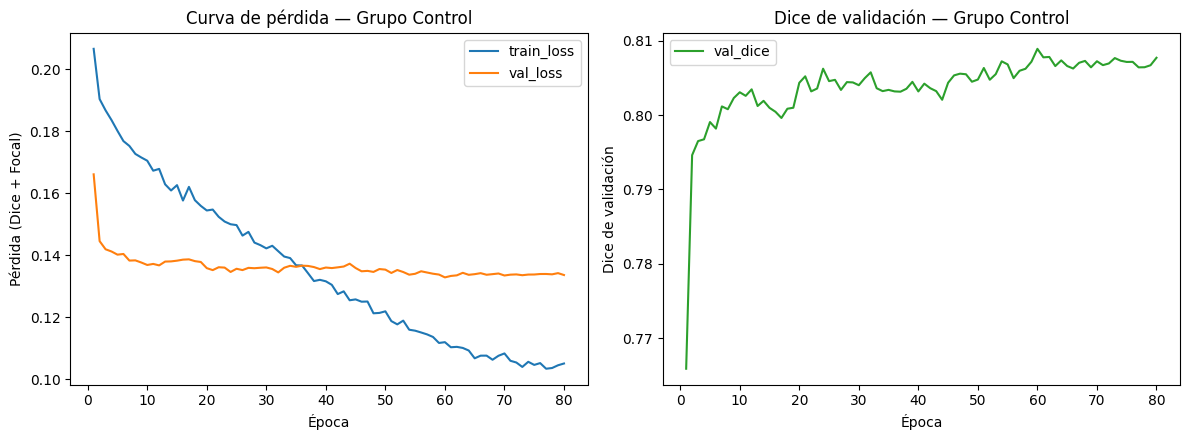

Figura de curvas de entrenamiento guardada en: /content/drive/MyDrive/KDD_Caries/Fase 4/Semilla 42/Salida/Control/Figuras/curvas_entrenamiento_control.png


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(historial["epoch"], historial["train_loss"], label="train_loss")
axes[0].plot(historial["epoch"], historial["val_loss"], label="val_loss")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Pérdida (Dice + Focal)")
axes[0].set_title(f"Curva de pérdida — Grupo {CONFIG.group_name}")
axes[0].legend()

axes[1].plot(historial["epoch"], historial["val_dice"], color="tab:green", label="val_dice")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Dice de validación")
axes[1].set_title(f"Dice de validación — Grupo {CONFIG.group_name}")
axes[1].legend()

plt.tight_layout()
ruta_figura = CONFIG.figures_dir / f"curvas_entrenamiento_{CONFIG.group_name.lower()}.png"
plt.savefig(ruta_figura, dpi=150)
plt.show()

print(f"Figura de curvas de entrenamiento guardada en: {ruta_figura}")

### 11.2. Inspección cualitativa: máscara real vs. máscara predicha

Se cargan los pesos del mejor *checkpoint* guardado durante el entrenamiento (Sección 10.3) y se ejecuta inferencia sobre un subconjunto fijo y determinista de muestras del conjunto de validación, con el único propósito de inspeccionar visualmente la calidad de la segmentación producida por `SAM2-{CONFIG.group_name}` frente a la máscara de referencia. Esta inspección es puramente cualitativa y se realiza sobre `valid`, no sobre `test`: no sustituye la evaluación cuantitativa formal ni la comparación estadística entre grupos, que corresponden a la Fase 5 y están fuera del alcance de este notebook.

Checkpoint cargado: /content/drive/MyDrive/KDD_Caries/Fase 4/Semilla 42/Salida/Control/Checkpoints/sam2_control_s42_20261002_033006_final_ema.pt (época 80, val_dice=0.8077)


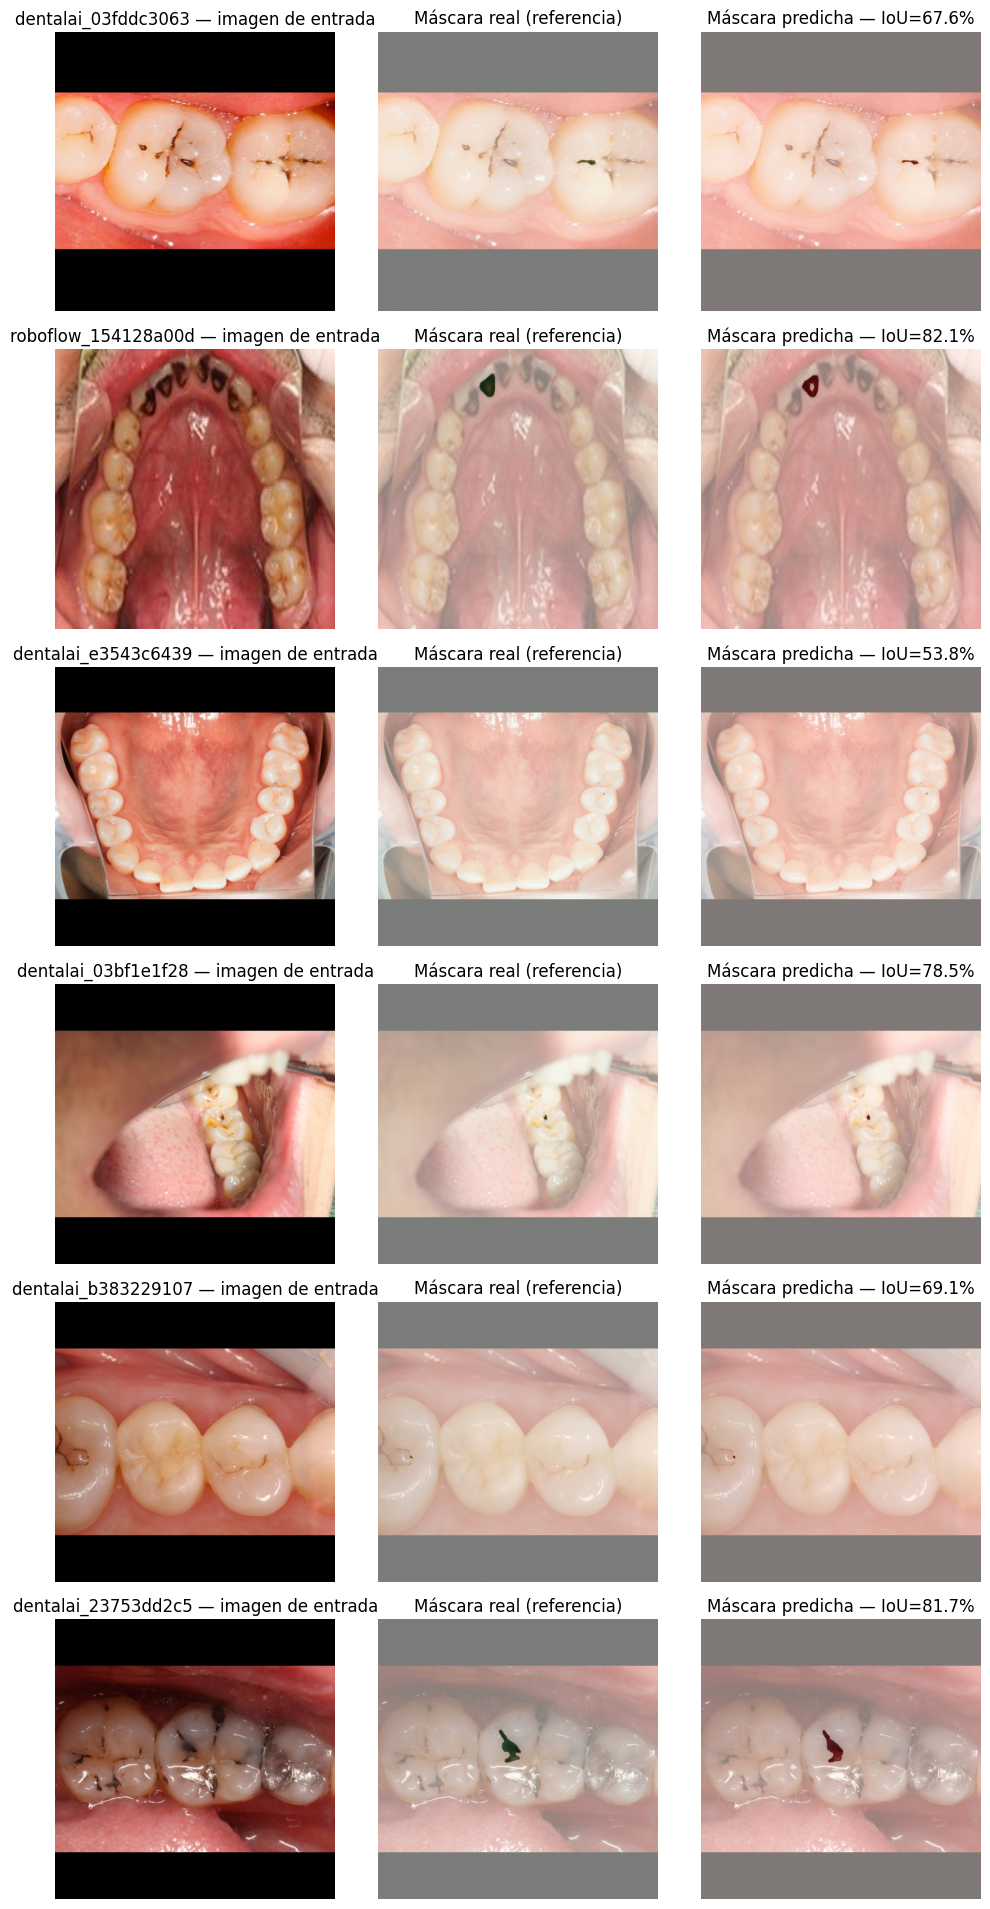

Figura de inspección cualitativa guardada en: /content/drive/MyDrive/KDD_Caries/Fase 4/Semilla 42/Salida/Control/Figuras/inspeccion_cualitativa_control.png


In [ ]:
def cargar_mejor_checkpoint(modelo, ruta_checkpoint: Path, device: str):
    """Carga en `modelo` los pesos del checkpoint indicado (modelo final EMA)."""
    estado = torch.load(ruta_checkpoint, map_location=device, weights_only=False)
    modelo.load_state_dict(estado["model_state_dict"])
    modelo.eval()
    print(f"Checkpoint cargado: {ruta_checkpoint} (época {estado['epoch']}, "
          f"val_dice={estado['val_dice']:.4f})")
    return modelo

@torch.no_grad()
def predecir_mascara(modelo, imagen: torch.Tensor, bbox_prompt: torch.Tensor, cfg: Phase4Config) -> np.ndarray:
    """Ejecuta inferencia sobre un único ejemplo y devuelve la máscara binaria predicha (H, W)."""
    batch_simulado = {
        "image": imagen.unsqueeze(0),
        "bbox_prompt": bbox_prompt.unsqueeze(0),
    }
    logits = forward_batch(modelo, batch_simulado, cfg)
    probs = torch.sigmoid(logits.squeeze(0))
    return (probs > 0.5).cpu().numpy().astype(np.uint8)

N_MUESTRAS_INSPECCION = 6
rng_inspeccion = np.random.default_rng(CONFIG.seed + 100)
indices_inspeccion = rng_inspeccion.choice(
    len(valid_dataset), size=min(N_MUESTRAS_INSPECCION, len(valid_dataset)), replace=False
)

sam2_model = cargar_mejor_checkpoint(sam2_model, ruta_final_checkpoint, CONFIG.device)

fig, axes = plt.subplots(len(indices_inspeccion), 3, figsize=(10, 3.2 * len(indices_inspeccion)))
if len(indices_inspeccion) == 1:
    axes = axes[np.newaxis, :]

resultados_inspeccion = []
for fila, idx in enumerate(indices_inspeccion):
    muestra = valid_dataset[int(idx)]
    imagen_np = (muestra["image"].permute(1, 2, 0).numpy() * 255).astype(np.uint8)
    mascara_real = muestra["mask"].numpy().astype(np.uint8)
    mascara_predicha = predecir_mascara(
        sam2_model,
        muestra["image"].to(CONFIG.device),
        muestra["bbox_prompt"].to(CONFIG.device),
        CONFIG,
    )

    interseccion = np.logical_and(mascara_real, mascara_predicha).sum()
    union = np.logical_or(mascara_real, mascara_predicha).sum()
    iou_pct = float(interseccion / union * 100) if union > 0 else 0.0
    resultados_inspeccion.append({"stem": muestra["stem"], "iou_pct": iou_pct})

    axes[fila, 0].imshow(imagen_np)
    axes[fila, 0].set_title(f"{muestra['stem']} — imagen de entrada")
    axes[fila, 0].axis("off")

    axes[fila, 1].imshow(imagen_np)
    axes[fila, 1].imshow(mascara_real, cmap="Greens", alpha=0.5)
    axes[fila, 1].set_title("Máscara real (referencia)")
    axes[fila, 1].axis("off")

    axes[fila, 2].imshow(imagen_np)
    axes[fila, 2].imshow(mascara_predicha, cmap="Reds", alpha=0.5)
    axes[fila, 2].set_title(f"Máscara predicha — IoU={iou_pct:.1f}%")
    axes[fila, 2].axis("off")

plt.tight_layout()
ruta_figura_inspeccion = CONFIG.figures_dir / f"inspeccion_cualitativa_{CONFIG.group_name.lower()}.png"
plt.savefig(ruta_figura_inspeccion, dpi=150)
plt.show()

print(f"Figura de inspección cualitativa guardada en: {ruta_figura_inspeccion}")

### 11.3. Cuantificación del solapamiento (IoU) por muestra

Se tabula y grafica el porcentaje de solapamiento (intersección sobre unión, expresada como porcentaje) entre máscara real y máscara predicha para el mismo subconjunto de la Sección 11.2, como complemento numérico directo de la inspección visual.

Solapamiento (IoU) por muestra — Grupo Control
               stem   iou_pct
dentalai_03fddc3063 67.643312
roboflow_154128a00d 82.088714
dentalai_e3543c6439 53.846154
dentalai_03bf1e1f28 78.531073
dentalai_b383229107 69.117647
dentalai_23753dd2c5 81.696325
IoU promedio del subconjunto de inspección: 72.2%


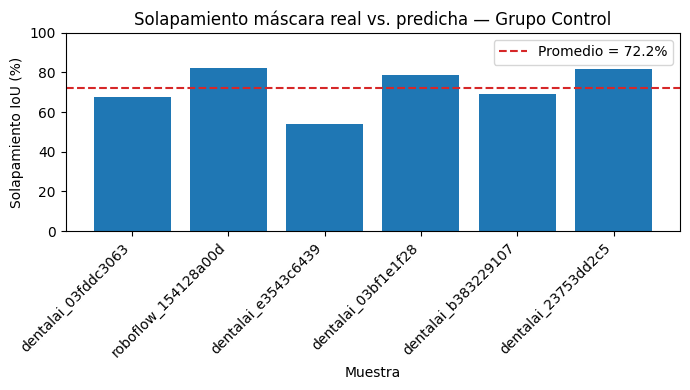

Figura y tabla de solapamiento guardadas en: /content/drive/MyDrive/KDD_Caries/Fase 4/Semilla 42/Salida/Control/Figuras y /content/drive/MyDrive/KDD_Caries/Fase 4/Semilla 42/Salida/Control/Logs


In [ ]:
df_inspeccion = pd.DataFrame(resultados_inspeccion)
print(f"Solapamiento (IoU) por muestra — Grupo {CONFIG.group_name}")
print(df_inspeccion.to_string(index=False))
print(f"IoU promedio del subconjunto de inspección: {df_inspeccion['iou_pct'].mean():.1f}%")

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(df_inspeccion["stem"], df_inspeccion["iou_pct"], color="tab:blue")
ax.axhline(
    df_inspeccion["iou_pct"].mean(), color="tab:red", linestyle="--",
    label=f"Promedio = {df_inspeccion['iou_pct'].mean():.1f}%",
)
ax.set_ylabel("Solapamiento IoU (%)")
ax.set_xlabel("Muestra")
ax.set_title(f"Solapamiento máscara real vs. predicha — Grupo {CONFIG.group_name}")
ax.set_ylim(0, 100)
plt.xticks(rotation=45, ha="right")
ax.legend()
plt.tight_layout()

ruta_figura_iou = CONFIG.figures_dir / f"solapamiento_iou_{CONFIG.group_name.lower()}.png"
plt.savefig(ruta_figura_iou, dpi=150)
plt.show()

df_inspeccion.to_csv(CONFIG.logs_dir / f"inspeccion_iou_{CONFIG.group_name.lower()}.csv", index=False)
print(f"Figura y tabla de solapamiento guardadas en: {CONFIG.figures_dir} y {CONFIG.logs_dir}")

Esta inspección cualitativa y su cuantificación de IoU por muestra se limitan al subconjunto de validación de este mismo grupo; en ningún momento comparan `SAM2-Control` con `SAM2-Experimental`, comparación que corresponde exclusivamente a la Fase 5 sobre el conjunto de prueba.

---

## 12. Resumen final

### 12.1. Configuración efectivamente usada

Tabla resumen de la configuración utilizada en este entrenamiento, lista para copiar a la sección de Métodos del artículo.

In [ ]:
resumen = {
    "Grupo": CONFIG.group_name,
    "data.yaml": str(CONFIG.data_yaml_path),
    "Arquitectura base": "SAM2 (Ravi et al., 2024)",
    "Estrategia": "Ajuste fino parcial (Image Encoder congelado, Prompt Encoder congelado, Mask Decoder entrenable)",
    "Prompt": f"{CONFIG.prompt_type} (padding={CONFIG.prompt_bbox_padding_px}px, jitter=±{CONFIG.prompt_bbox_jitter_frac:.2%} solo en train)",
    "Función de pérdida": f"Dice(w={CONFIG.loss_dice_weight}) + Focal(w={CONFIG.loss_focal_weight}, alpha={CONFIG.focal_alpha}, gamma={CONFIG.focal_gamma})",
    "Optimizador": f"{CONFIG.optimizer_name} (lr={CONFIG.learning_rate}, wd={CONFIG.weight_decay})",
    "Scheduler": f"{CONFIG.lr_scheduler_name} (T_max={CONFIG.lr_scheduler_t_max_epochs}, eta_min={CONFIG.lr_scheduler_eta_min})",
    "Batch size": CONFIG.batch_size,
    "Épocas": CONFIG.num_epochs,
    "Early stopping": "no se usa; se reporta la EMA de la última época",
    "EMA / recorte de gradiente": f"decay={CONFIG.ema_decay} / clip={CONFIG.grad_clip_norm}",
    "RUN_ID / huella de configuración": f"{RUN_ID} / {HUELLA_CONFIG}",
    "Precisión numérica": CONFIG.mixed_precision,
    "Semilla": CONFIG.seed,
    "Augmentaciones": "geométricas únicamente (hflip, rotate, shift-scale-rotate)",
    "Checkpoint final": str(ruta_final_checkpoint),
}

df_resumen = pd.DataFrame(list(resumen.items()), columns=["Parámetro", "Valor"])
print(df_resumen.to_string(index=False))

df_resumen.to_csv(CONFIG.logs_dir / f"resumen_configuracion_{CONFIG.group_name.lower()}.csv", index=False)

                       Parámetro                                                                                                                                             Valor
                           Grupo                                                                                                                                           Control
                       data.yaml                                     /content/drive/MyDrive/KDD_Caries/Fase 3/Salida/Control/data.yaml
               Arquitectura base                                                                                                                          SAM2 (Ravi et al., 2024)
                      Estrategia                                                  Ajuste fino parcial (Image Encoder congelado, Prompt Encoder congelado, Mask Decoder entrenable)
                          Prompt                                                                                                   bbox (padding=4px,

--
## 13. Exportación del modelo final para reutilización

### 13.1. Propósito

El checkpoint guardado en la Sección 10.3 (ruta_mejor_checkpoint) ya contiene los pesos finales del ajuste fino (model_state_dict) y es, en sí mismo, cargable desde cualquier otro entorno de Colab que tenga acceso a este mismo Google Drive y al paquete sam2 instalado. Esta sección no reentrena ni modifica ese checkpoint; únicamente lo empaqueta en una forma más liviana y documentada, pensada para ser reutilizada fuera de este notebook: (a) un archivo .pt "portable" que contiene solo los pesos del modelo (sin el estado del optimizador, innecesario para inferencia), (b) un .json de metadatos con la configuración y las métricas asociadas, y (c) una celda de referencia con el procedimiento exacto de carga en un Colab distinto.

In [ ]:
def sha256_archivo(ruta: Path, bloque: int = 8 * 1024 * 1024) -> str:
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for trozo in iter(lambda: f.read(bloque), b""):
            h.update(trozo)
    return h.hexdigest()

def version_paquete(nombre: str):
    try:
        return importlib.metadata.version(nombre)
    except Exception:
        return None

ruta_pesos_portables = CONFIG.output_root / f"SAM2-{CONFIG.group_name}_{RUN_ID}_pesos_finales.pt"
ruta_metadatos = CONFIG.output_root / f"SAM2-{CONFIG.group_name}_{RUN_ID}_metadatos.json"
assert not ruta_pesos_portables.exists(), "no se sobrescriben pesos exportados"

estado_final = torch.load(ruta_final_checkpoint, map_location="cpu", weights_only=False)

torch.save(
    {
        "model_state_dict": estado_final["model_state_dict"],
        "epoch": estado_final["epoch"],
        "val_dice": estado_final["val_dice"],
        "run_id": RUN_ID,
    },
    ruta_pesos_portables,
)

metadatos_exportacion = {
    "grupo": CONFIG.group_name,
    "run_id": RUN_ID,
    "semilla": CONFIG.seed,
    "huella_config": HUELLA_CONFIG,
    "arquitectura_base": "SAM2.1 Hiera Large (Ravi et al., 2024)",
    "sam2_model_cfg": CONFIG.sam2_model_cfg,
    "sam2_checkpoint_url": CONFIG.sam2_checkpoint_url,
    "epoca_modelo_final": estado_final["epoch"],
    "val_dice_modelo_final": estado_final["val_dice"],
    "checkpoint_final": str(ruta_final_checkpoint),
    "sha256_checkpoint_final": sha256_archivo(ruta_final_checkpoint),
    "checkpoint_mejor": str(ruta_mejor_checkpoint),
    "pesos_portables": str(ruta_pesos_portables),
    "sha256_pesos_portables": sha256_archivo(ruta_pesos_portables),
    "repetible_bitwise_prueba_humo": REPETIBLE_BITWISE,
    "versiones": {
        "python": platform.python_version(),
        "torch": torch.__version__,
        "albumentations": version_paquete("albumentations"),
        "numpy": np.__version__,
        "opencv": cv2.__version__,
        "sam2": version_paquete("SAM-2"),
    },
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "fecha_fin": dt.datetime.now().isoformat(timespec="seconds"),
    "config_entrenamiento": CONFIG.configuracion_como_dict(),
}

with open(ruta_metadatos, "w", encoding="utf-8") as f:
    json.dump(metadatos_exportacion, f, indent=2, ensure_ascii=False)

print(f"Pesos portables guardados en: {ruta_pesos_portables}")
print(f"Metadatos guardados en: {ruta_metadatos}")
print(f"SHA-256 del checkpoint final: {metadatos_exportacion['sha256_checkpoint_final']}")

Pesos portables guardados en: /content/drive/MyDrive/KDD_Caries/Fase 4/Semilla 42/Salida/Control/SAM2-Control_control_s42_20261002_033006_pesos_finales.pt
Metadatos guardados en: /content/drive/MyDrive/KDD_Caries/Fase 4/Semilla 42/Salida/Control/SAM2-Control_control_s42_20261002_033006_metadatos.json
SHA-256 del checkpoint final: 05ce392c262640b5e0b61eb58890318a40f999e3b1720584ba5c8f02e8148804


### 13.2. Evaluación rápida en prueba, ligada al checkpoint

Diagnóstico inmediato tras el entrenamiento: se evalúa el **modelo final** sobre las 564 lesiones de prueba con la caja del polígono más el margen fijo, **sin jitter** (oracle prompt), y se guardan las métricas por lesión junto con el hash del checkpoint que las produjo. Así una evaluación queda siempre asociada al archivo que la generó. **No sustituye a la Fase 5**, que sigue siendo la evaluación de referencia.

In [ ]:
test_dataset = CariesSegDataset("test", CONFIG, augment=False, jitter=False)
test_loader = DataLoader(test_dataset, batch_size=CONFIG.batch_size, shuffle=False,
                         num_workers=CONFIG.num_workers, worker_init_fn=worker_init_fn)

sam2_model = cargar_mejor_checkpoint(sam2_model, ruta_final_checkpoint, CONFIG.device)

filas_test = []
with torch.no_grad():
    for batch in test_loader:
        logits = forward_batch(sam2_model, batch, CONFIG)
        pred = (torch.sigmoid(logits) > 0.5).cpu().numpy().astype(bool)
        gt = (batch["mask"] > 0.5).numpy()
        for i in range(pred.shape[0]):
            tp = int(np.logical_and(pred[i], gt[i]).sum())
            fp = int(np.logical_and(pred[i], ~gt[i]).sum())
            fn = int(np.logical_and(~pred[i], gt[i]).sum())
            stem = batch["stem"][i]
            filas_test.append({
                "lesion_id": f"{stem}#{int(batch['lesion_idx'][i])}", "stem": stem, "fuente": stem.split("_")[0],
                "Dice": 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else 0.0,
                "IoU": tp / (tp + fp + fn) if (tp + fp + fn) > 0 else 0.0,
                "Precision": tp / (tp + fp) if (tp + fp) > 0 else 0.0,
                "Sensibilidad": tp / (tp + fn) if (tp + fn) > 0 else 0.0,
            })

df_test = pd.DataFrame(filas_test)
sha_final = metadatos_exportacion["sha256_checkpoint_final"]
df_test["run_id"] = RUN_ID
df_test["sha256_checkpoint"] = sha_final
ruta_eval_rapida = CONFIG.logs_dir / f"eval_rapida_test_{RUN_ID}.csv"
df_test.to_csv(ruta_eval_rapida, index=False)

print(f"Evaluación rápida en prueba — Grupo {CONFIG.group_name}, semilla {CONFIG.seed}, n={len(df_test)} lesiones")
print(f"Dice medio: {df_test['Dice'].mean():.4f} | IoU medio: {df_test['IoU'].mean():.4f}")
print(df_test.groupby("fuente")[["Dice", "IoU"]].mean().round(4).to_string())
print(f"Guardada en: {ruta_eval_rapida}")

metadatos_exportacion["eval_rapida_test"] = {
    "n_lesiones": int(len(df_test)), "dice_medio": float(df_test["Dice"].mean()),
    "iou_medio": float(df_test["IoU"].mean()), "archivo": str(ruta_eval_rapida),
}
with open(ruta_metadatos, "w", encoding="utf-8") as f:
    json.dump(metadatos_exportacion, f, indent=2, ensure_ascii=False)

[test] Imágenes: 156 | Lesiones (instancias): 564
Checkpoint cargado: /content/drive/MyDrive/KDD_Caries/Fase 4/Semilla 42/Salida/Control/Checkpoints/sam2_control_s42_20261002_033006_final_ema.pt (época 80, val_dice=0.8077)
Evaluación rápida en prueba — Grupo Control, semilla 42, n=564 lesiones
Dice medio: 0.8001 | IoU medio: 0.6854
            Dice     IoU
fuente                  
dentalai  0.7752  0.6565
roboflow  0.8386  0.7301
Guardada en: /content/drive/MyDrive/KDD_Caries/Fase 4/Semilla 42/Salida/Control/Logs/eval_rapida_test_control_s42_20261002_033006.csv


Este notebook solo incluye una **evaluación rápida en prueba** (Sección 13.2) como diagnóstico ligado al hash del checkpoint; la comparación formal entre grupos (Jaccard/Dice/F1, borde, calibración, inferencia estadística) corresponde a la Fase 5 (Interpretación y evaluación) y está fuera de su alcance.